# Módulo 07: Pandas

Autor: Juliho Castillo Colmenares

> Lección complementaria del ejercicio [m07-pandas.ipynb](m07-pandas.ipynb). No es una tarea entregada del programa.

Las listas y los diccionarios sirven para pocos datos, pero un análisis real trabaja con tablas de cientos o millones de filas. **pandas** es la librería estándar de Python para eso: carga archivos, filtra, transforma, resume por grupos y exporta, casi siempre en una sola línea y sin escribir ciclos. En esta lección usamos `iris.csv`, que contiene medidas en centímetros de 150 flores de tres especies de iris.

1. `Series` y `DataFrame`
2. Cargar e inspeccionar datos
3. Seleccionar columnas y filas: `loc` e `iloc`
4. Filtrar con condiciones
5. Columnas nuevas y operaciones vectorizadas
6. Agrupar y resumir: `groupby` y `agg`
7. Renombrar y exportar
8. Gráfico de dispersión por grupo
9. Errores frecuentes
10. Ejercicio

## 1. `Series` y `DataFrame`

pandas tiene dos estructuras principales:

| Estructura | Dimensiones | Se parece a |
| --- | --- | --- |
| `Series` | 1 (una columna) | Una lista con etiquetas |
| `DataFrame` | 2 (filas y columnas) | Una hoja de cálculo o tabla SQL |

Cada fila tiene una etiqueta, el **índice**, y cada columna de un `DataFrame` es una `Series`.

In [1]:
import io

import matplotlib.pyplot as plt
import pandas as pd

alturas = pd.Series([1.62, 1.75, 1.58], index=["Ana", "Luis", "Marta"], name="altura_m")
print(alturas)
print()

personas = pd.DataFrame({
    "nombre": ["Ana", "Luis", "Marta"],
    "edad": [28, 35, 41],
    "ciudad": ["Lima", "Quito", "Lima"],
})
print(personas)
print(type(personas["edad"]))   # una columna es una Series

Ana      1.62
Luis     1.75
Marta    1.58
Name: altura_m, dtype: float64

  nombre  edad ciudad
0    Ana    28   Lima
1   Luis    35  Quito
2  Marta    41   Lima
<class 'pandas.core.series.Series'>


## 2. Cargar e inspeccionar datos

`pd.read_csv` lee un archivo CSV y devuelve un `DataFrame`. Lo primero tras cargar unos datos es inspeccionarlos:

| Herramienta | Muestra |
| --- | --- |
| `df.head(n)` | Las primeras `n` filas (5 por defecto) |
| `df.shape` | Tupla `(filas, columnas)` |
| `df.info()` | Tipos de cada columna y valores no nulos |
| `df.describe()` | Estadísticos de las columnas numéricas |

In [2]:
iris = pd.read_csv("iris.csv")

print(iris.shape)
iris.head()

(150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


Las 150 filas tienen valores en todas las columnas. `Id` es solo un número de registro, así que conviene excluirla de los resúmenes estadísticos. La fila `50%` de `describe` es la mediana.

In [4]:
iris.drop(columns="Id").describe().round(2)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.00,150.00,150.00,150.00
mean,5.84,3.05,3.76,1.20
std,0.83,0.43,1.76,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


## 3. Seleccionar columnas y filas: `loc` e `iloc`

- Una columna se obtiene con `df["columna"]` (una `Series`); varias, con una lista: `df[["a", "b"]]` (un `DataFrame`).
- `df.loc[filas, columnas]` selecciona por **etiqueta**: nombres de columna y valores del índice. Con `loc`, el extremo final de un rango **sí se incluye**.
- `df.iloc[filas, columnas]` selecciona por **posición**, como el slicing de listas: el extremo final no se incluye.

In [5]:
print(iris["Species"].unique())

print(iris.loc[0:2, ["SepalLengthCm", "Species"]])   # etiquetas 0, 1 y 2
print()
print(iris.iloc[0:2, [1, 5]])                         # posiciones 0 y 1

['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']
   SepalLengthCm      Species
0            5.1  Iris-setosa
1            4.9  Iris-setosa
2            4.7  Iris-setosa

   SepalLengthCm      Species
0            5.1  Iris-setosa
1            4.9  Iris-setosa


## 4. Filtrar con condiciones

Una comparación sobre una columna devuelve una `Series` de booleanos, una **máscara**, que se usa entre corchetes para quedarse con las filas `True`. Para combinar condiciones se usan `&` (y), `|` (o) y `~` (no), **cada condición entre paréntesis**.

Los paréntesis son obligatorios porque `&` y `|` tienen más prioridad que `>` o `==`.

In [6]:
mascara = iris["PetalLengthCm"] > 6
print(mascara.sum(), "flores con pétalo de más de 6 cm")   # True cuenta como 1

grandes_y_anchas = iris[(iris["SepalLengthCm"] > 7) & (iris["SepalWidthCm"] >= 3)]
print(grandes_y_anchas[["SepalLengthCm", "SepalWidthCm", "Species"]])

9 flores con pétalo de más de 6 cm
     SepalLengthCm  SepalWidthCm         Species
102            7.1           3.0  Iris-virginica
105            7.6           3.0  Iris-virginica
109            7.2           3.6  Iris-virginica
117            7.7           3.8  Iris-virginica
125            7.2           3.2  Iris-virginica
129            7.2           3.0  Iris-virginica
131            7.9           3.8  Iris-virginica
135            7.7           3.0  Iris-virginica


In [7]:
extremas = iris[(iris["SepalWidthCm"] < 2.3) | (iris["SepalWidthCm"] > 4.0)]
print(len(extremas), "flores con sépalo muy estrecho o muy ancho")

no_setosa = iris[~(iris["Species"] == "Iris-setosa")]
print(no_setosa["Species"].value_counts())

7 flores con sépalo muy estrecho o muy ancho
Species
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


## 5. Columnas nuevas y operaciones vectorizadas

Las operaciones aritméticas entre columnas se aplican **elemento a elemento** a toda la columna, sin ciclos: es lo que se llama una operación **vectorizada**. El resultado se guarda como columna nueva con `df["nueva"] = ...`.

Un caso típico es la **estandarización** (puntuación z), que expresa cada valor en desviaciones estándar respecto a la media:

$$z_i = \frac{x_i - \bar{x}}{s}$$

donde $\bar{x}$ es la media y $s$ la desviación estándar. `Series.std()` de pandas calcula la desviación **muestral** (divide entre $n - 1$). Tras estandarizar, la columna tiene media 0 y desviación 1.

In [8]:
datos = iris.copy()     # copia para no modificar el original

datos["ratio_sepalo"] = datos["SepalLengthCm"] / datos["SepalWidthCm"]

largo = datos["SepalLengthCm"]
datos["largo_sepalo_z"] = (largo - largo.mean()) / largo.std()

print(datos[["SepalLengthCm", "ratio_sepalo", "largo_sepalo_z"]].head().round(3))
print("media z:", round(datos["largo_sepalo_z"].mean(), 6) + 0.0,   # + 0.0 evita mostrar -0.0
      " desviación z:", round(datos["largo_sepalo_z"].std(), 6))

   SepalLengthCm  ratio_sepalo  largo_sepalo_z
0            5.1         1.457          -0.898
1            4.9         1.633          -1.139
2            4.7         1.469          -1.381
3            4.6         1.484          -1.501
4            5.0         1.389          -1.018
media z: 0.0  desviación z: 1.0


## 6. Agrupar y resumir: `groupby` y `agg`

`groupby("columna")` divide la tabla en grupos según los valores de esa columna; luego se aplica una función de resumen a cada grupo. Con `agg` y **agregaciones con nombre** se eligen varias estadísticas a la vez y el nombre de cada columna del resultado:

```python
df.groupby("grupo").agg(nombre_resultado=("columna", "función"))
```

Las funciones más usadas son `"count"`, `"mean"`, `"median"`, `"std"`, `"min"` y `"max"`. `reset_index()` convierte la columna de grupo de nuevo en una columna normal.

In [9]:
resumen = iris.groupby("Species").agg(
    n=("SepalLengthCm", "count"),
    largo_medio=("SepalLengthCm", "mean"),
    largo_mediana=("SepalLengthCm", "median"),
    ancho_max=("SepalWidthCm", "max"),
).reset_index()

resumen.round(2)

,Species,n,largo_medio,largo_mediana,ancho_max
0,Iris-setosa,50,5.01,5.0,4.4
1,Iris-versicolor,50,5.94,5.9,3.4
2,Iris-virginica,50,6.59,6.5,3.8


Para contar filas por grupo también sirve `value_counts()`, y para el total de filas de un `DataFrame`, `len(df)` o `df.shape[0]`.

In [10]:
print(iris["Species"].value_counts())
print("Total de filas:", len(iris))

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64
Total de filas: 150


## 7. Renombrar y exportar

`rename(columns={"viejo": "nuevo"})` cambia los nombres de las columnas y devuelve un `DataFrame` nuevo; el original no cambia salvo que se reasigne.

`to_csv(ruta, index=False)` guarda el `DataFrame` en un archivo; `index=False` evita escribir el índice como primera columna. Aquí se escribe en un `io.StringIO`, un "archivo" en memoria, para ver el contenido sin crear nada en disco.

In [11]:
tabla = resumen[["Species", "n", "largo_medio"]].rename(columns={
    "Species": "Especie",
    "n": "Flores",
    "largo_medio": "Largo medio del sépalo",
})

buffer = io.StringIO()
tabla.round(2).to_csv(buffer, index=False)
print(buffer.getvalue())

Especie,Flores,Largo medio del sépalo
Iris-setosa,50,5.01
Iris-versicolor,50,5.94
Iris-virginica,50,6.59



## 8. Gráfico de dispersión por grupo

Un diagrama de dispersión muestra la relación entre dos variables numéricas. Para distinguir grupos se recorre el resultado de `groupby`, que entrega pares `(nombre_del_grupo, sub_DataFrame)`, y se dibuja cada grupo con su propia etiqueta.

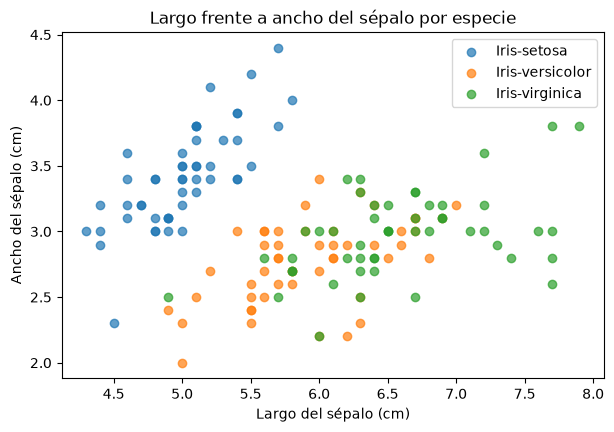

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for especie, grupo in iris.groupby("Species"):
    ax.scatter(grupo["SepalLengthCm"], grupo["SepalWidthCm"], label=especie, alpha=0.7)

ax.set_title("Largo frente a ancho del sépalo por especie")
ax.set_xlabel("Largo del sépalo (cm)")
ax.set_ylabel("Ancho del sépalo (cm)")
ax.legend()
plt.show()

En el sépalo, *Iris setosa* forma un grupo aparte, con sépalos más cortos y anchos, mientras que *versicolor* y *virginica* se solapan bastante.

## 9. Errores frecuentes

**Asignar una columna sobre un subconjunto filtrado.** Un filtro como `df[df["x"] > 0]` devuelve un subconjunto que pandas no sabe si es una copia o una vista del original. Si después se le asigna una columna, pandas emite un `SettingWithCopyWarning`: avisa de que el cambio quizá no llegue a donde se espera. La solución es crear el subconjunto con `.copy()`, que deja claro que es un `DataFrame` independiente.

Para mostrar el aviso sin ensuciar la salida, aquí se captura con `warnings.catch_warnings`:

In [13]:
import warnings

with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    largas = iris[iris["PetalLengthCm"] > 5]          # subconjunto sin copiar
    largas["doble"] = largas["PetalLengthCm"] * 2
print("Sin .copy():", [a.category.__name__ for a in avisos])

with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    largas = iris[iris["PetalLengthCm"] > 5].copy()   # subconjunto independiente
    largas["doble"] = largas["PetalLengthCm"] * 2
print("Con .copy():", [a.category.__name__ for a in avisos])
print("¿El original cambió?", "doble" in iris.columns)

Sin .copy(): ['SettingWithCopyWarning']
Con .copy(): []
¿El original cambió? False


**Usar `and` y `or` en lugar de `&` y `|`.** `and` necesita un único `True` o `False`, y una `Series` tiene muchos; pandas lanza un `ValueError` porque no sabe cómo reducirla a un solo valor.

In [14]:
try:
    iris[(iris["SepalLengthCm"] > 7) and (iris["SepalWidthCm"] >= 3)]
except ValueError as error:
    print("ValueError:", error)

print(len(iris[(iris["SepalLengthCm"] > 7) & (iris["SepalWidthCm"] >= 3)]), "filas con &")

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().
8 filas con &


**Omitir los paréntesis en un filtro compuesto.** Sin ellos, `iris["SepalLengthCm"] > 7 & iris["SepalWidthCm"] >= 3` se evalúa como `iris["SepalLengthCm"] > (7 & iris["SepalWidthCm"]) >= 3`, que no es lo que se quería y suele terminar en error. Cada condición va entre paréntesis.

**Esperar que `rename` o `drop` modifiquen el original.** Devuelven un `DataFrame` nuevo; hay que guardarlo en una variable (`df = df.rename(...)`).

In [15]:
copia = iris.head(2)
copia.rename(columns={"Species": "Especie"})      # el resultado se pierde
print(list(copia.columns)[-1])

copia = copia.rename(columns={"Species": "Especie"})
print(list(copia.columns)[-1])

Species
Especie


## 10. Ejercicio

Con `iris.csv`:

1. Crea una columna `area_petalo` con el producto del largo por el ancho del pétalo, como aproximación de su tamaño.
2. Quédate con las flores de las especies *versicolor* o *virginica* cuyo `area_petalo` sea mayor que 7. Usa `.copy()`.
3. En ese subconjunto, crea `area_z`, la puntuación z de `area_petalo`.
4. Agrupa por especie y calcula, con agregaciones con nombre, el número de flores, el área media y el `area_z` máximo.
5. Renombra las columnas del resumen al español y muestra el CSV resultante con `io.StringIO`, con dos decimales.

### Solución

In [16]:
flores = iris.copy()
flores["area_petalo"] = flores["PetalLengthCm"] * flores["PetalWidthCm"]

seleccion = flores[
    ((flores["Species"] == "Iris-versicolor") | (flores["Species"] == "Iris-virginica"))
    & (flores["area_petalo"] > 7)
].copy()

area = seleccion["area_petalo"]
seleccion["area_z"] = (area - area.mean()) / area.std()

resumen_area = seleccion.groupby("Species").agg(
    flores=("area_petalo", "count"),
    area_media=("area_petalo", "mean"),
    area_z_max=("area_z", "max"),
).reset_index()

resumen_area = resumen_area.rename(columns={
    "Species": "Especie",
    "flores": "Flores",
    "area_media": "Área media (cm²)",
    "area_z_max": "Área z máxima",
})

buffer = io.StringIO()
resumen_area.round(2).to_csv(buffer, index=False)
print(buffer.getvalue())

Especie,Flores,Área media (cm²),Área z máxima
Iris-versicolor,8,7.72,-0.91
Iris-virginica,50,11.3,2.14



Las 50 flores *virginica* superan los 7 cm² de área (su mínimo es 7.5), mientras que de *versicolor* solo pasan el filtro 8. Por eso el área z máxima de *versicolor* es negativa: incluso sus pétalos más grandes quedan por debajo de la media del subconjunto, dominado por *virginica*.

## Resumen

- Un `DataFrame` es una tabla de `Series` con índice; `read_csv` la carga y `head`, `shape`, `info` y `describe` permiten inspeccionarla.
- `loc` selecciona por etiqueta (incluye el extremo final) e `iloc` por posición (lo excluye).
- Los filtros combinan máscaras con `&`, `|` y `~`, siempre con cada condición entre paréntesis.
- Las operaciones entre columnas son vectorizadas; para asignar columnas nuevas a un subconjunto filtrado, este se crea con `.copy()`.
- `groupby` con `agg` resume por grupos con nombres claros; `rename` y `to_csv(index=False)` preparan y exportan el resultado.

En el **Módulo 08** se presenta NumPy, la librería de arreglos numéricos sobre la que está construido pandas.